# Results 

This notebook implements the experiments for the paper: Neural Forecasting of Rainfall-Distribution Shifts Using Deterministic Uncertainty Measures

and focused on two research questions:

**RQ1:** To what extent do LSTM, GRU, TCN, and TFT-style attention models improve rainfall-distribution shift forecasting compared with conventional machine-learning and statistical baselines?

**RQ2:** How are deterministic uncertainty methods useful to quantify rainfall-distribution shifts?

The notebook supports replication by including daily rainfall loading, data auditing, hydrological-year aggregation, deterministic rainfall-shift target construction, benchmark models, neural models, chronological splitting, regression metrics, paired neural-vs-baseline analysis, reference-window sensitivity, and paper-ready outputs.

Important interpretation: the notebook forecasts and analyses rainfall-distribution shifts. It does **not** claim to directly predict flood occurrence.

## 1. Imports, configuration, and reproducibility settings

In [1]:
from pathlib import Path
import math
import json
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except Exception:
    HAS_XGBOOST = False

try:
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    from statsmodels.tsa.arima.model import ARIMA
    HAS_STATSMODELS = True
except Exception:
    HAS_STATSMODELS = False

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    HAS_TORCH = True
except Exception:
    HAS_TORCH = False

DATA_DIR = Path("/mnt/data") if Path("/mnt/data").exists() else Path(".")
OUTPUT_DIR = DATA_DIR / "flood_rq1_rq2_experiment_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

if HAS_TORCH:
    torch.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    DEVICE = None

CONFIG = {
    "hydrological_year_start_month": 7,
    "minimum_daily_records_per_hydrological_year": 300,
    "reference_years": 20,
    "lookback_years": 6,
    "train_fraction": 0.70,
    "validation_fraction": 0.15,
    "random_seed": RANDOM_SEED,
    "targets": ["KL_q1", "DW_q1", "DB_q1", "EMD_q1"],
    "neural_max_epochs": 600,
    "neural_patience": 80,
    "neural_learning_rate": 1e-3,
    "neural_weight_decay": 1e-4,
    "neural_dropout": 0.10,
    "gradient_clip_norm": 1.0
}

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print("Output directory:", OUTPUT_DIR)
print("PyTorch available:", HAS_TORCH, "| Device:", DEVICE)
print("XGBoost available:", HAS_XGBOOST)
print("statsmodels available:", HAS_STATSMODELS)

Output directory: flood_rq1_rq2_experiment_outputs
PyTorch available: True | Device: cpu
XGBoost available: True
statsmodels available: True


## 2. Dataset discovery

The notebook searches for daily rainfall files in the working directory. Expected files include:

- `2024_07_Catamarca.csv`, 
- `2024_07_Cordoba.csv`
- `2024_07_Lamadrid.csv`, if available

If a station file is unavailable, that station is skipped rather than imputed.

In [2]:
def robust_read_csv(path):
    attempts = [
        dict(sep=",", engine="python"),
        dict(sep=";", engine="python"),
        dict(sep=None, engine="python"),
        dict(sep="\t", engine="python"),
    ]
    last_error = None
    for kwargs in attempts:
        try:
            df = pd.read_csv(path, **kwargs)
            if df.shape[1] >= 2:
                return df
        except Exception as exc:
            last_error = exc
    raise last_error

def first_existing(candidates):
    for name in candidates:
        p = DATA_DIR / name
        if p.exists():
            return p
    return None

STATION_FILES = {
    "Catamarca": first_existing([        
        "2024_07_Catamarca.csv"
    ]),
    "Cordoba": first_existing([
        "2024_07_Cordoba.csv"       
    ]),
    "LaMadrid": first_existing([
        "2024_07_Lamadrid.csv"        
    ])
}

STATION_FILES = {k: v for k, v in STATION_FILES.items() if v is not None}
print("Detected station files:")
for k, v in STATION_FILES.items():
    print(f"  {k}: {v}")

if not STATION_FILES:
    raise FileNotFoundError("No station rainfall files were found in DATA_DIR.")

Detected station files:
  Catamarca: 2024_07_Catamarca.csv
  Cordoba: 2024_07_Cordoba.csv
  LaMadrid: 2024_07_Lamadrid.csv


## 3. Daily rainfall parsing and data audit

In [3]:
def find_col(df, candidates):
    lower_map = {str(c).strip().lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    for c in df.columns:
        cc = str(c).strip().lower()
        for cand in candidates:
            if cand.lower() in cc:
                return c
    return None

def hydrological_year(dates, start_month=7):
    return np.where(dates.dt.month >= start_month, dates.dt.year, dates.dt.year - 1)

def parse_daily_rainfall(path, station):
    raw = robust_read_csv(path)

    year_col = find_col(raw, ["YEAR", "year", "año", "ano"])
    month_col = find_col(raw, ["MO", "MONTH", "month", "mes"])
    day_col = find_col(raw, ["DY", "DAY", "day", "dia", "día"])
    date_col = find_col(raw, ["date", "fecha", "ds", "time"])
    rain_col = find_col(raw, [
        "PRECTOTCORR", "PRECTOT", "rain_mm", "rain", "rainfall",
        "precip", "precipitation", "precipitacion", "precipitación", "mm"
    ])

    if date_col is not None:
        ds = pd.to_datetime(raw[date_col], errors="coerce", dayfirst=True)
    elif year_col and month_col and day_col:
        ds = pd.to_datetime(
            dict(
                year=pd.to_numeric(raw[year_col], errors="coerce"),
                month=pd.to_numeric(raw[month_col], errors="coerce"),
                day=pd.to_numeric(raw[day_col], errors="coerce")
            ),
            errors="coerce"
        )
    else:
        raise ValueError(f"Could not identify date columns in {path.name}. Columns: {list(raw.columns)}")

    if rain_col is None:
        raise ValueError(f"Could not identify rainfall column in {path.name}. Columns: {list(raw.columns)}")

    rain_raw = pd.to_numeric(raw[rain_col], errors="coerce")
    audit = {
        "station": station,
        "file": path.name,
        "raw_rows": len(raw),
        "invalid_dates": int(ds.isna().sum()),
        "non_numeric_rain": int(rain_raw.isna().sum()),
        "negative_rain_values": int((rain_raw < 0).sum(skipna=True)),
        "duplicate_dates": int(ds.duplicated().sum())
    }

    df = pd.DataFrame({"station": station, "ds": ds, "rain_mm": rain_raw}).dropna(subset=["ds"])
    df["rain_mm"] = pd.to_numeric(df["rain_mm"], errors="coerce").fillna(0).clip(lower=0)
    df = df.groupby(["station", "ds"], as_index=False)["rain_mm"].mean()
    df = df.sort_values("ds").reset_index(drop=True)
    df["hydro_year"] = hydrological_year(df["ds"], CONFIG["hydrological_year_start_month"])

    audit.update({
        "parsed_rows": len(df),
        "date_min": str(df["ds"].min().date()),
        "date_max": str(df["ds"].max().date()),
        "zero_rain_fraction": float((df["rain_mm"] == 0).mean()),
        "mean_daily_rain_mm": float(df["rain_mm"].mean()),
        "median_daily_rain_mm": float(df["rain_mm"].median()),
        "p95_daily_rain_mm": float(df["rain_mm"].quantile(0.95)),
        "max_daily_rain_mm": float(df["rain_mm"].max())
    })
    return df, audit

daily_tables, audit_rows = [], []
for station, path in STATION_FILES.items():
    df, audit = parse_daily_rainfall(path, station)
    daily_tables.append(df)
    audit_rows.append(audit)

daily = pd.concat(daily_tables, ignore_index=True)
daily_audit = pd.DataFrame(audit_rows)
daily_audit.to_csv(OUTPUT_DIR / "daily_data_audit.csv", index=False)

display(daily_audit)
display(daily.head())

,station,file,raw_rows,invalid_dates,non_numeric_rain,negative_rain_values,duplicate_dates,parsed_rows,date_min,date_max,zero_rain_fraction,mean_daily_rain_mm,median_daily_rain_mm,p95_daily_rain_mm,max_daily_rain_mm
0,Catamarca,2024_07_Catamarca.csv,15888,0,0,0,0,15888,1981-01-01,2024-07-01,0.552555,1.346489,0.0,7.633,244.70
1,Cordoba,2024_07_Cordoba.csv,15888,0,0,0,0,15888,1981-01-01,2024-07-01,0.516302,2.235390,0.0,13.510,139.90
2,LaMadrid,2024_07_Lamadrid.csv,15888,0,0,0,0,15888,1981-01-01,2024-07-01,0.531659,2.146644,0.0,12.736,195.31


,station,ds,rain_mm,hydro_year
0,Catamarca,1981-01-01,0.61,1980
1,Catamarca,1981-01-02,0.19,1980
2,Catamarca,1981-01-03,0.00,1980
3,Catamarca,1981-01-04,4.17,1980
4,Catamarca,1981-01-05,0.76,1980


## 4. Exploratory data analysis figures

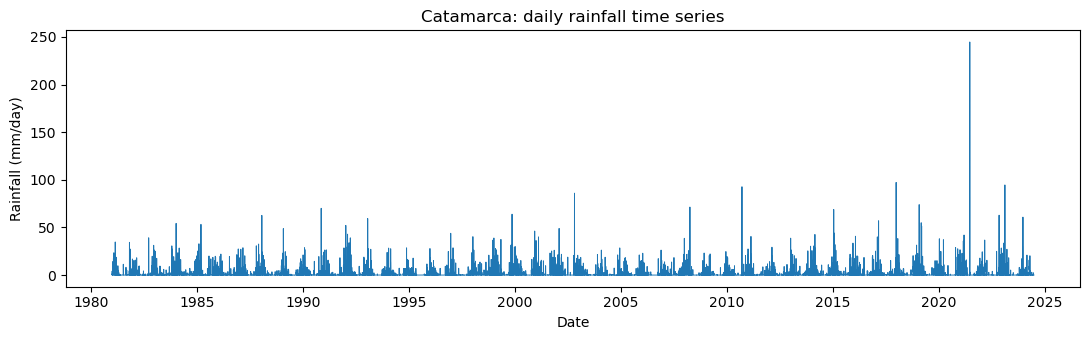

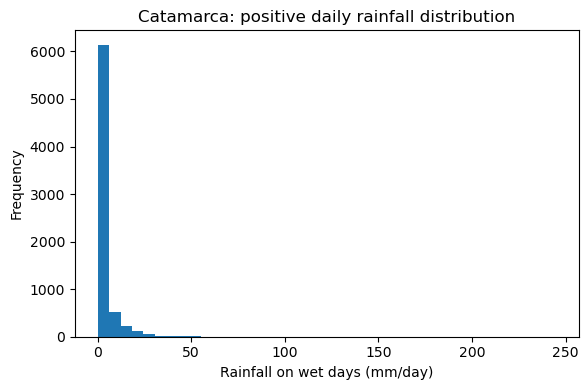

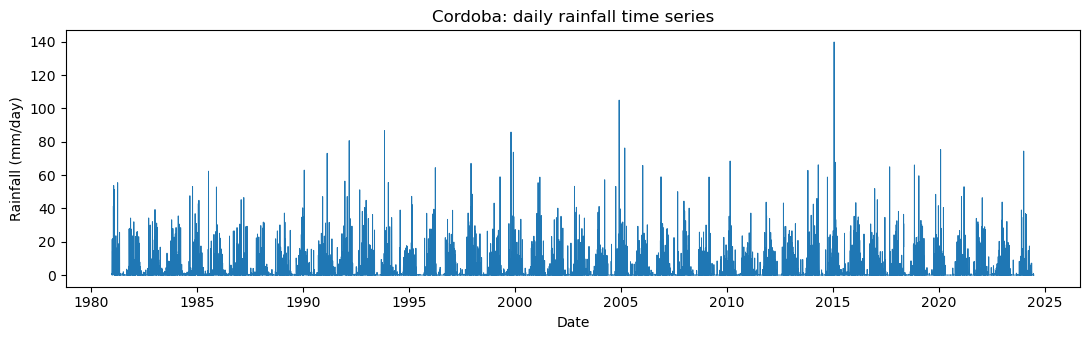

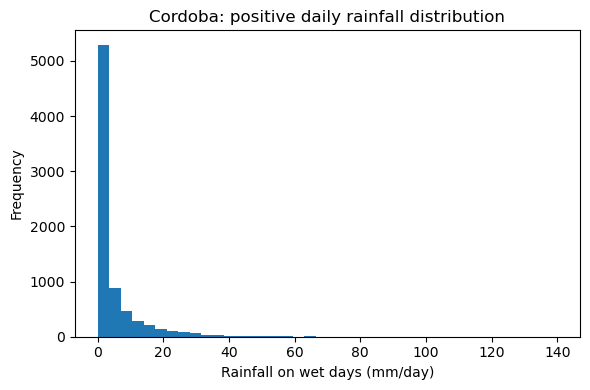

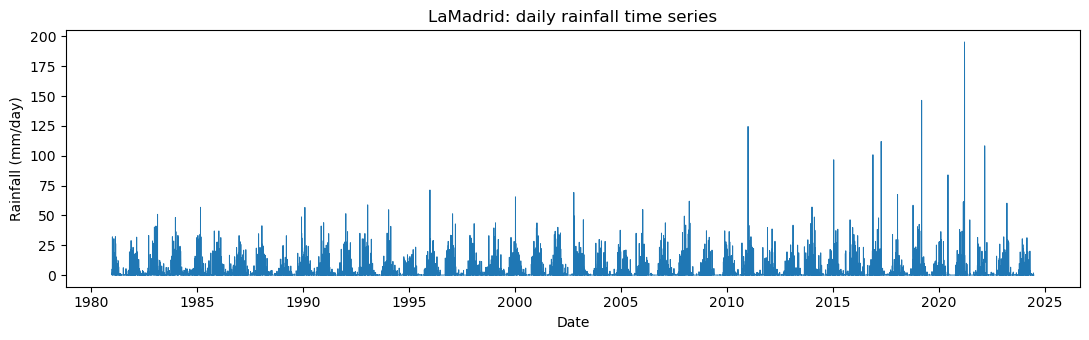

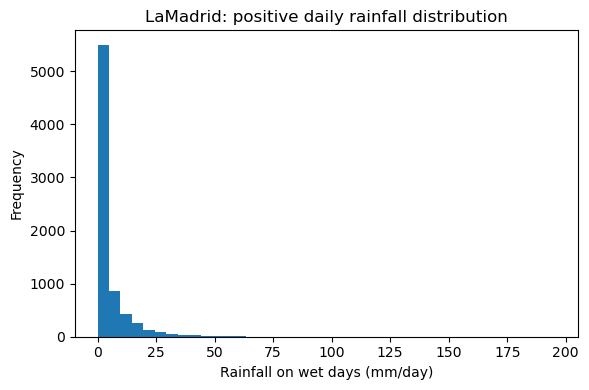

In [4]:
for station, g in daily.groupby("station"):
    g = g.sort_values("ds")

    plt.figure(figsize=(11, 3.5))
    plt.plot(g["ds"], g["rain_mm"], linewidth=0.7)
    plt.title(f"{station}: daily rainfall time series")
    plt.xlabel("Date")
    plt.ylabel("Rainfall (mm/day)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"EDA_daily_rainfall_timeseries_{station}.png", dpi=300)
    plt.show()

    positive = g.loc[g["rain_mm"] > 0, "rain_mm"]
    plt.figure(figsize=(6, 4))
    plt.hist(positive, bins=40)
    plt.title(f"{station}: positive daily rainfall distribution")
    plt.xlabel("Rainfall on wet days (mm/day)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"EDA_positive_daily_rainfall_histogram_{station}.png", dpi=300)
    plt.show()

## 5. Annual rainfall descriptors

In [5]:
def annual_descriptors_for_station(df_station, min_days=300):
    rows = []
    for hy, g in df_station.groupby("hydro_year"):
        g = g.sort_values("ds").reset_index(drop=True)
        if len(g) < min_days:
            continue

        rain = g["rain_mm"].to_numpy(dtype=float)
        total = float(np.nansum(rain))
        if not np.isfinite(total) or total <= 0:
            continue

        csum = np.cumsum(rain)
        frac = csum / max(csum[-1], 1e-12)
        idx16 = int(np.argmin(np.abs(frac - 0.1587)))
        idx50 = int(np.argmin(np.abs(frac - 0.5000)))
        idx84 = int(np.argmin(np.abs(frac - 0.8413)))

        rows.append({
            "station": g["station"].iloc[0],
            "hydro_year": int(hy),
            "annual_precip_mm": total,
            "wet_days": int((rain >= 1.0).sum()),
            "rx1day_mm": float(np.max(rain)),
            "rx3day_mm": float(pd.Series(rain).rolling(3, min_periods=1).sum().max()),
            "rx5day_mm": float(pd.Series(rain).rolling(5, min_periods=1).sum().max()),
            "rx7day_mm": float(pd.Series(rain).rolling(7, min_periods=1).sum().max()),
            "mean_daily_rain_mm": float(np.mean(rain)),
            "q15_87_day": float(idx16),
            "mu_day": float(idx50),
            "q84_13_day": float(idx84),
            "sigma_left": float(max(idx50 - idx16, 1)),
            "sigma_right": float(max(idx84 - idx50, 1)),
            "sigma": float(max(0.5 * (idx84 - idx16), 1)),
            "valid_daily_count": int(len(g)),
            "zero_rain_fraction": float((rain == 0).mean())
        })
    return pd.DataFrame(rows)

annual = pd.concat(
    [annual_descriptors_for_station(g, CONFIG["minimum_daily_records_per_hydrological_year"])
     for _, g in daily.groupby("station")],
    ignore_index=True
).sort_values(["station", "hydro_year"]).reset_index(drop=True)

annual.to_csv(OUTPUT_DIR / "annual_rainfall_descriptors.csv", index=False)
display(annual.head())
display(annual.groupby("station").agg(
    years=("hydro_year", "count"),
    first_year=("hydro_year", "min"),
    last_year=("hydro_year", "max"),
    mean_annual_precip=("annual_precip_mm", "mean"),
    mean_wet_days=("wet_days", "mean"),
    mean_rx1=("rx1day_mm", "mean"),
    mean_rx5=("rx5day_mm", "mean")
).reset_index())

,station,hydro_year,annual_precip_mm,wet_days,rx1day_mm,rx3day_mm,rx5day_mm,rx7day_mm,mean_daily_rain_mm,q15_87_day,mu_day,q84_13_day,sigma_left,sigma_right,sigma,valid_daily_count,zero_rain_fraction
0,Catamarca,1981,436.45,67,34.35,46.21,53.01,57.70,1.195753,120.0,183.0,244.0,63.0,61.0,62.0,365,0.457534
1,Catamarca,1982,567.91,78,39.12,42.97,72.39,82.97,1.555918,147.0,189.0,238.0,42.0,49.0,45.5,365,0.468493
2,Catamarca,1983,644.50,92,54.25,65.16,67.19,77.22,1.760929,129.0,195.0,258.0,66.0,63.0,64.5,366,0.418033
3,Catamarca,1984,473.08,58,53.21,64.86,87.61,88.03,1.296110,166.0,220.0,255.0,54.0,35.0,44.5,365,0.482192
4,Catamarca,1985,479.91,68,22.01,39.09,44.82,62.80,1.314822,96.0,172.0,237.0,76.0,65.0,70.5,365,0.484932


,station,years,first_year,last_year,mean_annual_precip,mean_wet_days,mean_rx1,mean_rx5
0,Catamarca,43,1981,2023,489.260233,66.465116,52.212791,72.784884
1,Cordoba,43,1981,2023,808.128837,89.000000,58.681860,95.417674
2,LaMadrid,43,1981,2023,780.403953,90.558140,59.585581,102.267674


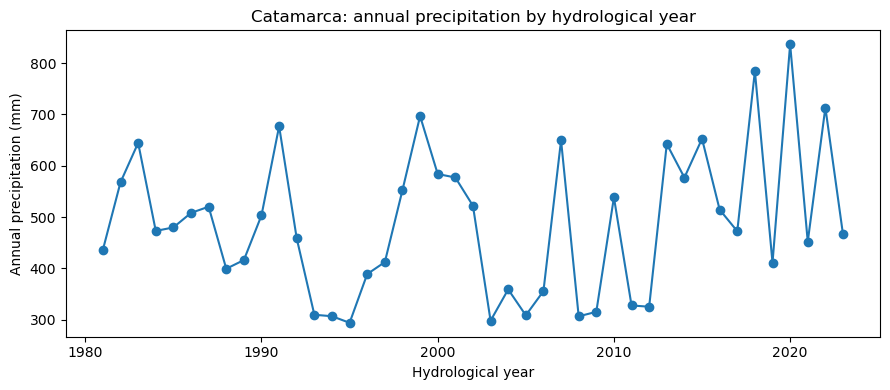

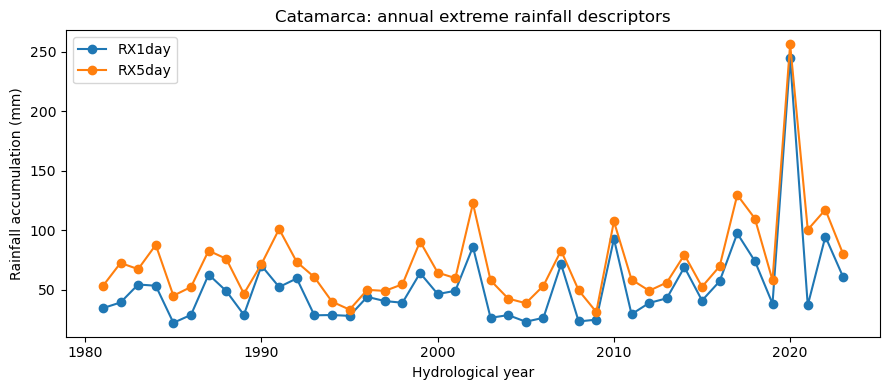

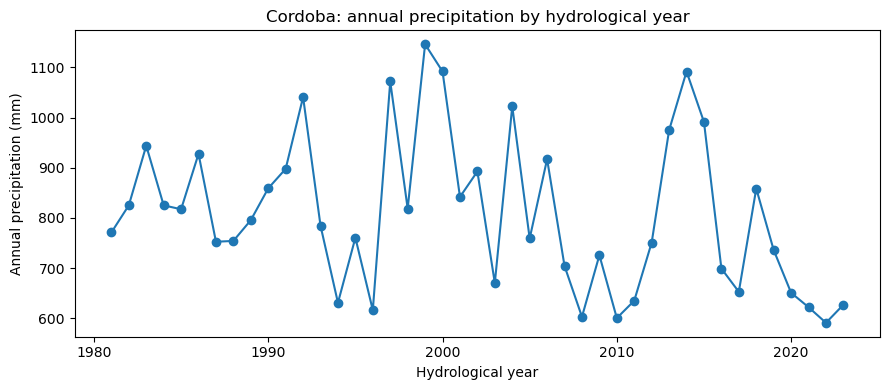

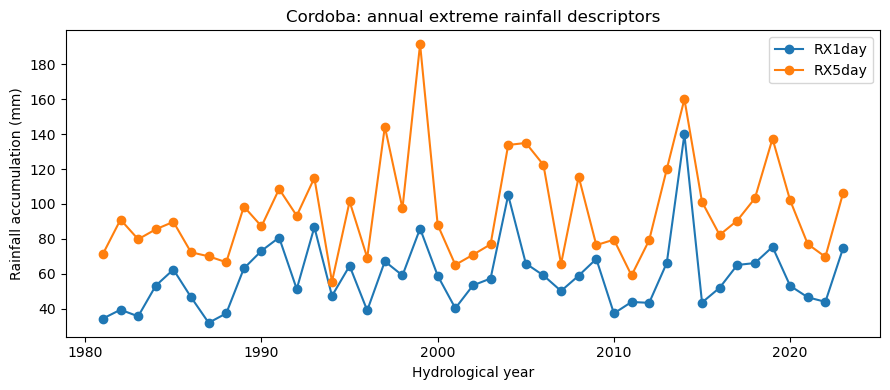

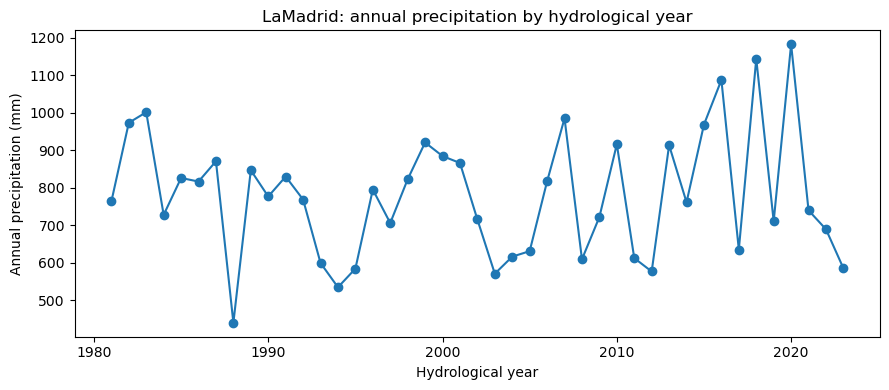

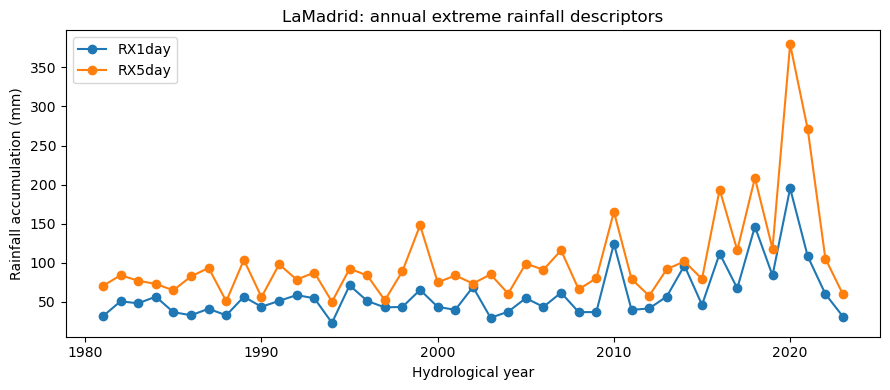

In [6]:
for station, g in annual.groupby("station"):
    plt.figure(figsize=(9, 4))
    plt.plot(g["hydro_year"], g["annual_precip_mm"], marker="o")
    plt.title(f"{station}: annual precipitation by hydrological year")
    plt.xlabel("Hydrological year")
    plt.ylabel("Annual precipitation (mm)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"EDA_annual_precipitation_{station}.png", dpi=300)
    plt.show()

    plt.figure(figsize=(9, 4))
    plt.plot(g["hydro_year"], g["rx1day_mm"], marker="o", label="RX1day")
    plt.plot(g["hydro_year"], g["rx5day_mm"], marker="o", label="RX5day")
    plt.title(f"{station}: annual extreme rainfall descriptors")
    plt.xlabel("Hydrological year")
    plt.ylabel("Rainfall accumulation (mm)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"EDA_extreme_rainfall_descriptors_{station}.png", dpi=300)
    plt.show()

## 6. Rainfall-distribution shift targets and deterministic uncertainty measures

This section constructs the deterministic uncertainty/divergence measures used for RQ2:

- **KL divergence**: information-theoretic departure from the reference distribution.
- **Wasserstein-style distance**: displacement between reference and annual rainfall-timing distributions.
- **Bhattacharyya distance**: reduction in distributional overlap.
- **Earth Mover's Distance**: transport-cost-style distributional difference.

The implementation uses rainfall-timing descriptors from the cumulative annual rainfall curve. The `q1`, `q2`, and `qmean` components represent lower-side spread, upper-side spread, and mean spread departures.

In [7]:
def gaussian_divergence_components(mu_p, sigma_p, mu_q, sigma_q):
    # Deterministic distribution-shift measures between simplified Gaussian timing summaries.
    sigma_p = max(float(sigma_p), 1e-6)
    sigma_q = max(float(sigma_q), 1e-6)
    mu_p = float(mu_p)
    mu_q = float(mu_q)

    kl = np.log(sigma_q / sigma_p) + (sigma_p**2 + (mu_p - mu_q)**2) / (2 * sigma_q**2) - 0.5
    wasserstein_style = (mu_p - mu_q)**2 + (np.sqrt(sigma_p) - np.sqrt(sigma_q))**2
    bhattacharyya = 0.25 * ((mu_p - mu_q)**2) / (sigma_p**2 + sigma_q**2) + 0.5 * np.log((sigma_p**2 + sigma_q**2) / (2 * sigma_p * sigma_q))
    emd_style = abs(mu_p - mu_q) + abs(sigma_p - sigma_q)
    return kl, wasserstein_style, bhattacharyya, emd_style

def add_deterministic_uncertainty_measures(annual_df, reference_years=20):
    out = []
    for station, g in annual_df.groupby("station"):
        g = g.sort_values("hydro_year").reset_index(drop=True).copy()
        ref = g.head(min(reference_years, len(g)))
        mu_ref = float(ref["mu_day"].median())
        sigma_ref = float(ref["sigma"].median())

        for suffix, sig_col in [("q1", "sigma_left"), ("q2", "sigma_right"), ("qmean", "sigma")]:
            vals = np.array([
                gaussian_divergence_components(mu_ref, sigma_ref, row.mu_day, getattr(row, sig_col))
                for row in g.itertuples(index=False)
            ])
            g[f"KL_{suffix}"] = vals[:, 0]
            g[f"DW_{suffix}"] = vals[:, 1]
            g[f"DB_{suffix}"] = vals[:, 2]
            g[f"EMD_{suffix}"] = vals[:, 3]

        g["reference_mu_day"] = mu_ref
        g["reference_sigma"] = sigma_ref
        out.append(g)

    return pd.concat(out, ignore_index=True)

annual_div = add_deterministic_uncertainty_measures(annual, CONFIG["reference_years"])
annual_div.to_csv(OUTPUT_DIR / "annual_rainfall_shift_deterministic_uncertainty_targets.csv", index=False)

display(annual_div.head())
print("Divergence columns:", [c for c in annual_div.columns if c.startswith(("KL_", "DW_", "DB_", "EMD_"))])

,station,hydro_year,annual_precip_mm,wet_days,rx1day_mm,rx3day_mm,rx5day_mm,rx7day_mm,mean_daily_rain_mm,q15_87_day,...,KL_q2,DW_q2,DB_q2,EMD_q2,KL_qmean,DW_qmean,DB_qmean,EMD_qmean,reference_mu_day,reference_sigma
0,Catamarca,1981,436.45,67,34.35,46.21,53.01,57.70,1.195753,120.0,...,0.027847,182.301699,0.007356,17.0,0.029109,182.334758,0.007790,18.0,196.5,57.5
1,Catamarca,1982,567.91,78,39.12,42.97,72.39,82.97,1.555918,147.0,...,0.040264,56.589744,0.008834,16.0,0.078027,56.951417,0.016190,19.5,196.5,57.5
2,Catamarca,1983,644.50,92,54.25,65.16,67.19,77.22,1.760929,129.0,...,0.008142,2.375584,0.002161,7.0,0.012513,2.450985,0.003367,8.5,196.5,57.5
3,Catamarca,1984,473.08,58,53.21,64.86,87.61,88.03,1.296110,166.0,...,0.578461,555.028208,0.089705,46.0,0.217950,553.081823,0.042361,36.5,196.5,57.5
4,Catamarca,1985,479.91,68,22.01,39.09,44.82,62.80,1.314822,96.0,...,0.084910,600.479807,0.023674,32.0,0.096816,600.911867,0.028446,37.5,196.5,57.5


Divergence columns: ['KL_q1', 'DW_q1', 'DB_q1', 'EMD_q1', 'KL_q2', 'DW_q2', 'DB_q2', 'EMD_q2', 'KL_qmean', 'DW_qmean', 'DB_qmean', 'EMD_qmean']


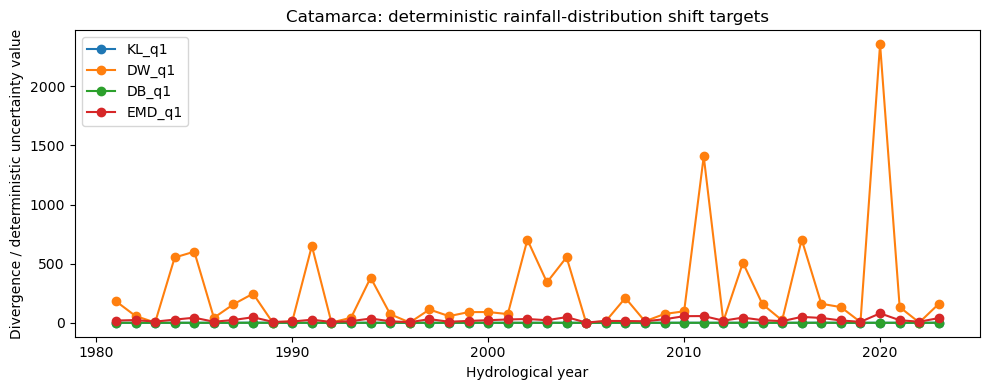

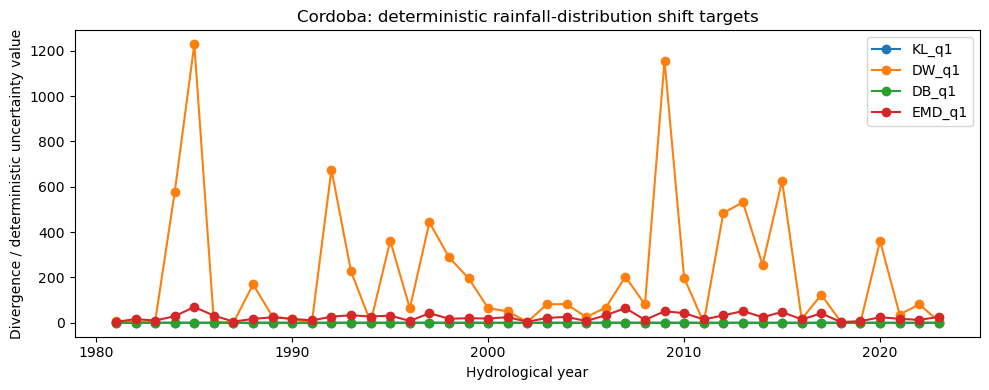

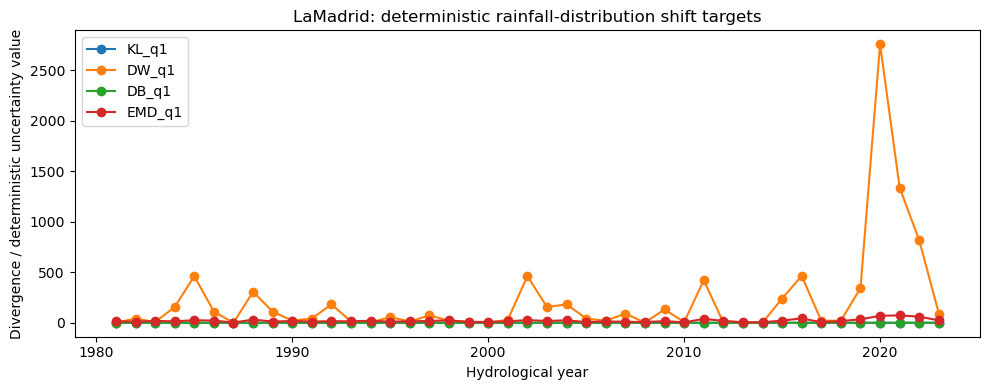

In [8]:
TARGETS = [t for t in CONFIG["targets"] if t in annual_div.columns]

for station, g in annual_div.groupby("station"):
    plt.figure(figsize=(10, 4))
    for target in TARGETS:
        plt.plot(g["hydro_year"], g[target], marker="o", label=target)
    plt.title(f"{station}: deterministic rainfall-distribution shift targets")
    plt.xlabel("Hydrological year")
    plt.ylabel("Divergence / deterministic uncertainty value")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"RQ2_deterministic_uncertainty_targets_{station}.png", dpi=300)
    plt.show()

## 7. RQ2 diagnostic analysis of deterministic uncertainty measures

KL_q1                                               DW_q1  \
               mean       std       min    median       max        mean   
station                                                                   
Catamarca  0.150446  0.257652  0.000688  0.070827  1.329462  260.486384   
Cordoba    0.088595  0.093609  0.000895  0.059551  0.378841  205.643198   
LaMadrid   0.059465  0.070087  0.001240  0.039203  0.317955  215.831382   

                                                            DB_q1            \
                  std       min     median          max      mean       std   
station                                                                       
Catamarca  432.616823  0.259657  97.089081  2355.676592  0.029452  0.036053   
Cordoba    292.585282  0.761404  81.053177  1228.741380  0.021606  0.020852   
LaMadrid   471.448357  0.267545  42.419948  2757.375061  0.016744  0.021693   

                                            EMD_q1                          \
                min    median       max       mean        std   min median   
station                                                                      
Catamarca  0.000175  0.015071  0.158369  25.279070  16.916216  2.00  22.00   
Cordoba    0.000220  0.014069  0.083155  24.924419  15.902562  3.25  24.25   
LaMadrid   0.000317  0.008582  0.098770  20.523256  15.941095  2.50  16.50   

                  
             max  
station           
Catamarca  80.00  
Cordoba    69.75  
LaMadrid   73.50

,station,target,feature,spearman_rho,p_value
27,Catamarca,DB_q1,rx7day_mm,0.245394,0.112717
26,Catamarca,DB_q1,rx5day_mm,0.239203,0.122380
25,Catamarca,DB_q1,rx3day_mm,0.197221,0.204922
24,Catamarca,DB_q1,rx1day_mm,0.177974,0.253534
32,Catamarca,DB_q1,sigma_right,0.071221,0.649943
29,Catamarca,DB_q1,mu_day,0.061499,0.695233
22,Catamarca,DB_q1,annual_precip_mm,0.024917,0.873983
28,Catamarca,DB_q1,mean_daily_rain_mm,0.024917,0.873983
30,Catamarca,DB_q1,sigma,0.021754,0.889875
23,Catamarca,DB_q1,wet_days,-0.030465,0.846233


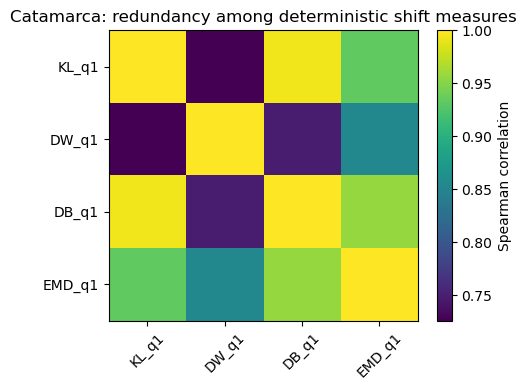

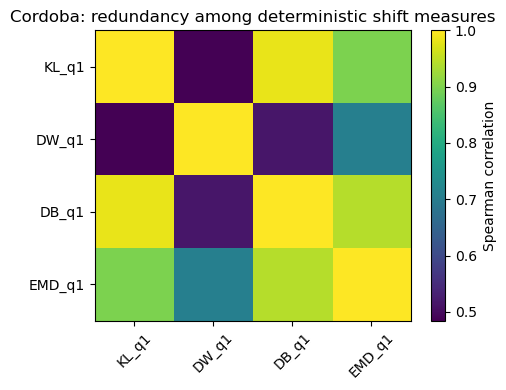

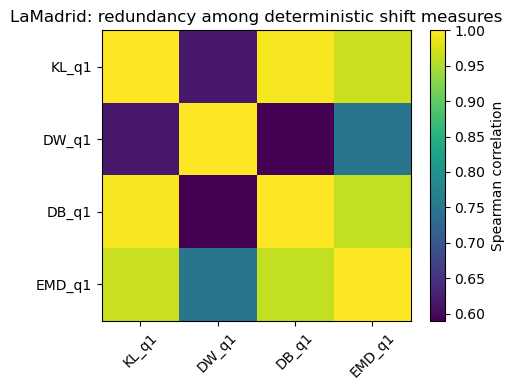

In [9]:
rq2_summary = annual_div.groupby("station")[TARGETS].agg(["mean", "std", "min", "median", "max"])
rq2_summary.to_csv(OUTPUT_DIR / "RQ2_deterministic_uncertainty_summary_statistics.csv")
display(rq2_summary)

rainfall_descriptor_cols = [
    "annual_precip_mm", "wet_days", "rx1day_mm", "rx3day_mm", "rx5day_mm", "rx7day_mm",
    "mean_daily_rain_mm", "mu_day", "sigma", "sigma_left", "sigma_right"
]

corr_rows = []
for station, g in annual_div.groupby("station"):
    for target in TARGETS:
        for feature in rainfall_descriptor_cols:
            if feature in g.columns and g[target].nunique() > 1 and g[feature].nunique() > 1:
                rho, p = stats.spearmanr(g[target], g[feature], nan_policy="omit")
                corr_rows.append({
                    "station": station,
                    "target": target,
                    "feature": feature,
                    "spearman_rho": rho,
                    "p_value": p
                })

rq2_correlations = pd.DataFrame(corr_rows).sort_values(["station", "target", "spearman_rho"], ascending=[True, True, False])
rq2_correlations.to_csv(OUTPUT_DIR / "RQ2_deterministic_uncertainty_correlations.csv", index=False)
display(rq2_correlations.head(30))

for station, g in annual_div.groupby("station"):
    if len(TARGETS) >= 2:
        corr = g[TARGETS].corr(method="spearman")
        corr.to_csv(OUTPUT_DIR / f"RQ2_divergence_redundancy_spearman_{station}.csv")
        plt.figure(figsize=(5, 4))
        plt.imshow(corr, aspect="auto")
        plt.xticks(range(len(TARGETS)), TARGETS, rotation=45)
        plt.yticks(range(len(TARGETS)), TARGETS)
        plt.colorbar(label="Spearman correlation")
        plt.title(f"{station}: redundancy among deterministic shift measures")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"RQ2_divergence_redundancy_heatmap_{station}.png", dpi=300)
        plt.show()

## 8. Supervised forecasting dataset

In [10]:
FEATURE_COLS_BASE = [
    "annual_precip_mm", "wet_days", "rx1day_mm", "rx3day_mm", "rx5day_mm", "rx7day_mm",
    "mean_daily_rain_mm", "mu_day", "sigma", "sigma_left", "sigma_right"
]
DIVERGENCE_COLS = [c for c in annual_div.columns if c.startswith(("KL_", "DW_", "DB_", "EMD_"))]
FEATURE_COLS = list(dict.fromkeys([c for c in FEATURE_COLS_BASE + DIVERGENCE_COLS if c in annual_div.columns]))

def make_supervised_station_target(df, station, target, feature_cols, lookback=6):
    g = df[df["station"] == station].sort_values("hydro_year").reset_index(drop=True)
    local_features = [c for c in feature_cols if c in g.columns]

    X_seq, y, years = [], [], []
    for i in range(lookback, len(g)):
        # Use only previous years. The target year is never included in the input window.
        X_seq.append(g.loc[i-lookback:i-1, local_features].to_numpy(float))
        y.append(float(g.loc[i, target]))
        years.append(int(g.loc[i, "hydro_year"]))

    return np.asarray(X_seq), np.asarray(y), np.asarray(years), local_features

def chronological_split(n, train_frac=0.70, val_frac=0.15):
    if n < 8:
        return None, None, None
    n_train = max(4, int(n * train_frac))
    n_val = max(2, int(n * val_frac))
    if n_train + n_val >= n:
        n_train = max(4, n - 3)
        n_val = max(1, n - n_train - 2)
    idx_train = np.arange(0, n_train)
    idx_val = np.arange(n_train, n_train + n_val)
    idx_test = np.arange(n_train + n_val, n)
    if len(idx_test) == 0:
        idx_test = np.array([n-1])
        idx_val = np.arange(n_train, n-1)
    return idx_train, idx_val, idx_test

dataset_rows = []
for station in annual_div["station"].unique():
    for target in TARGETS:
        X, y, years, fcols = make_supervised_station_target(
            annual_div, station, target, FEATURE_COLS, CONFIG["lookback_years"]
        )
        tr, va, te = chronological_split(len(y), CONFIG["train_fraction"], CONFIG["validation_fraction"])
        if tr is None:
            continue
        dataset_rows.append({
            "station": station,
            "target": target,
            "n_supervised": len(y),
            "n_features": len(fcols),
            "lookback": CONFIG["lookback_years"],
            "n_train": len(tr),
            "n_val": len(va),
            "n_test": len(te),
            "first_target_year": int(years[0]) if len(years) else None,
            "last_target_year": int(years[-1]) if len(years) else None
        })

forecast_dataset_summary = pd.DataFrame(dataset_rows)
forecast_dataset_summary.to_csv(OUTPUT_DIR / "forecast_dataset_summary.csv", index=False)
display(forecast_dataset_summary)

,station,target,n_supervised,n_features,lookback,n_train,n_val,n_test,first_target_year,last_target_year
0,Catamarca,KL_q1,37,23,6,25,5,7,1987,2023
1,Catamarca,DW_q1,37,23,6,25,5,7,1987,2023
2,Catamarca,DB_q1,37,23,6,25,5,7,1987,2023
3,Catamarca,EMD_q1,37,23,6,25,5,7,1987,2023
4,Cordoba,KL_q1,37,23,6,25,5,7,1987,2023
5,Cordoba,DW_q1,37,23,6,25,5,7,1987,2023
6,Cordoba,DB_q1,37,23,6,25,5,7,1987,2023
7,Cordoba,EMD_q1,37,23,6,25,5,7,1987,2023
8,LaMadrid,KL_q1,37,23,6,25,5,7,1987,2023
9,LaMadrid,DW_q1,37,23,6,25,5,7,1987,2023


## 9. Metrics

In [11]:
def forecast_metrics(y_true, y_pred, y_train):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    y_train = np.asarray(y_train, dtype=float).ravel()

    mse = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)

    train_naive_scale = np.mean(np.abs(np.diff(y_train))) if len(y_train) > 1 else np.nan
    mase = mae / train_naive_scale if np.isfinite(train_naive_scale) and train_naive_scale > 1e-12 else np.nan

    rng = np.nanmax(y_true) - np.nanmin(y_true)
    nrmse = rmse / rng if rng > 1e-12 else np.nan

    denom = np.sum((y_true - np.nanmean(y_true)) ** 2)
    nmse = np.sum((y_true - y_pred) ** 2) / denom if denom > 1e-12 else np.nan

    return {
        "MSE": float(mse),
        "RMSE": float(rmse),
        "MAE": float(mae),
        "MASE": float(mase) if np.isfinite(mase) else np.nan,
        "nRMSE": float(nrmse) if np.isfinite(nrmse) else np.nan,
        "NMSE": float(nmse) if np.isfinite(nmse) else np.nan
    }

## 10. Benchmark algorithms

In [12]:
def scale_flat_train_val_test(X_train, X_val, X_test):
    scaler = StandardScaler()
    X_train_f = X_train.reshape(len(X_train), -1)
    X_val_f = X_val.reshape(len(X_val), -1)
    X_test_f = X_test.reshape(len(X_test), -1)

    X_train_s = scaler.fit_transform(X_train_f)
    X_val_s = scaler.transform(X_val_f)
    X_test_s = scaler.transform(X_test_f)
    return X_train_s, X_val_s, X_test_s, scaler

def fit_predict_benchmarks(X_train, y_train, X_val, y_val, X_test):
    X_train_s, X_val_s, X_test_s, scaler = scale_flat_train_val_test(X_train, X_val, X_test)
    X_trainval_s = np.vstack([X_train_s, X_val_s])
    y_trainval = np.concatenate([y_train, y_val])

    results = {}
    results["Persistence"] = np.repeat(y_trainval[-1], len(X_test))
    results["Climatology"] = np.repeat(np.mean(y_train), len(X_test))

    for name, model in [
        ("LinearRegression", LinearRegression()),
        ("Ridge", Ridge(alpha=1.0, random_state=RANDOM_SEED))
    ]:
        model.fit(X_train_s, y_train)
        results[name] = model.predict(X_test_s)

    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=2,
        random_state=RANDOM_SEED
    )
    rf.fit(X_train_s, y_train)
    results["RandomForest"] = rf.predict(X_test_s)

    mlp = MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=2000,
        early_stopping=True,
        random_state=RANDOM_SEED
    )
    try:
        mlp.fit(X_train_s, y_train)
        results["MLP_flat"] = mlp.predict(X_test_s)
    except Exception as exc:
        print("MLP failed:", exc)

    if HAS_XGBOOST:
        xgb = XGBRegressor(
            n_estimators=200,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="reg:squarederror",
            random_state=RANDOM_SEED,
            n_jobs=1
        )
        xgb.fit(X_train_s, y_train)
        results["XGBoost"] = xgb.predict(X_test_s)

    if HAS_STATSMODELS:
        horizon = len(X_test)
        history = pd.Series(y_trainval)

        try:
            es = ExponentialSmoothing(history, trend="add", seasonal=None, initialization_method="estimated").fit()
            results["ExpSmoothing"] = np.asarray(es.forecast(horizon))
        except Exception as exc:
            print("Exponential smoothing failed:", exc)

        arima_orders = [(1,0,0), (0,1,1), (1,1,0), (1,1,1), (2,0,0), (0,0,1)]
        best_aic = np.inf
        best_forecast = None
        for order in arima_orders:
            try:
                model = ARIMA(history, order=order).fit()
                if model.aic < best_aic:
                    best_aic = model.aic
                    best_forecast = np.asarray(model.forecast(horizon))
            except Exception:
                pass
        if best_forecast is not None:
            results["BoundedARIMA"] = best_forecast

    return results

## 11. Neural algorithms

In [13]:
if HAS_TORCH:
    class LSTMRegressor(nn.Module):
        def __init__(self, n_features, hidden=24, dropout=0.10):
            super().__init__()
            self.rnn = nn.LSTM(n_features, hidden, batch_first=True)
            self.drop = nn.Dropout(dropout)
            self.head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
        def forward(self, x):
            out, _ = self.rnn(x)
            return self.head(self.drop(out[:, -1, :])).squeeze(-1)

    class GRURegressor(nn.Module):
        def __init__(self, n_features, hidden=24, dropout=0.10):
            super().__init__()
            self.rnn = nn.GRU(n_features, hidden, batch_first=True)
            self.drop = nn.Dropout(dropout)
            self.head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
        def forward(self, x):
            out, _ = self.rnn(x)
            return self.head(self.drop(out[:, -1, :])).squeeze(-1)

    class Chomp1d(nn.Module):
        def __init__(self, chomp):
            super().__init__()
            self.chomp = chomp
        def forward(self, x):
            return x[:, :, :-self.chomp] if self.chomp > 0 else x

    class TCNRegressor(nn.Module):
        def __init__(self, n_features, channels=16, levels=2, kernel_size=2, dropout=0.10):
            super().__init__()
            layers = []
            in_ch = n_features
            for i in range(levels):
                dilation = 2 ** i
                padding = (kernel_size - 1) * dilation
                layers.extend([
                    nn.Conv1d(in_ch, channels, kernel_size, padding=padding, dilation=dilation),
                    Chomp1d(padding),
                    nn.ReLU(),
                    nn.Dropout(dropout)
                ])
                in_ch = channels
            self.net = nn.Sequential(*layers)
            self.head = nn.Sequential(nn.Linear(channels, 16), nn.ReLU(), nn.Linear(16, 1))
        def forward(self, x):
            z = x.transpose(1, 2)
            z = self.net(z)
            return self.head(z[:, :, -1]).squeeze(-1)

    class TFTStyleRegressor(nn.Module):
        def __init__(self, n_features, hidden=24, heads=2, dropout=0.10):
            super().__init__()
            self.proj = nn.Linear(n_features, hidden)
            self.gru = nn.GRU(hidden, hidden, batch_first=True)
            self.attn = nn.MultiheadAttention(hidden, num_heads=heads, batch_first=True, dropout=dropout)
            self.gate = nn.Sequential(nn.Linear(hidden, hidden), nn.Sigmoid())
            self.drop = nn.Dropout(dropout)
            self.head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
        def forward(self, x):
            z = torch.relu(self.proj(x))
            z, _ = self.gru(z)
            a, _ = self.attn(z, z, z)
            pooled = a.mean(dim=1)
            gated = pooled * self.gate(pooled)
            return self.head(self.drop(gated)).squeeze(-1)

    NEURAL_CLASSES = {
        "LSTM": LSTMRegressor,
        "GRU": GRURegressor,
        "TCN": TCNRegressor,
        "TFT_style": TFTStyleRegressor
    }
else:
    NEURAL_CLASSES = {}
    print("Skipping neural algorithms because PyTorch is unavailable.")

In [14]:
def scale_sequence_train_val_test(X_train, X_val, X_test):
    n_train, lag, nf = X_train.shape
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train.reshape(n_train, -1)).reshape(n_train, lag, nf)
    X_val_s = scaler.transform(X_val.reshape(len(X_val), -1)).reshape(len(X_val), lag, nf)
    X_test_s = scaler.transform(X_test.reshape(len(X_test), -1)).reshape(len(X_test), lag, nf)
    return X_train_s, X_val_s, X_test_s, scaler

def train_neural_model(model_class, X_train, y_train, X_val, y_val):
    n_features = X_train.shape[-1]
    model = model_class(n_features).to(DEVICE)

    y_mean = float(np.mean(y_train))
    y_std = float(np.std(y_train))
    if y_std < 1e-12:
        y_std = 1.0

    y_train_s = (y_train - y_mean) / y_std
    y_val_s = (y_val - y_mean) / y_std

    ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train_s, dtype=torch.float32)
    )
    dl = DataLoader(ds, batch_size=min(16, len(ds)), shuffle=True)

    Xv = torch.tensor(X_val, dtype=torch.float32).to(DEVICE)
    yv = torch.tensor(y_val_s, dtype=torch.float32).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CONFIG["neural_learning_rate"],
        weight_decay=CONFIG["neural_weight_decay"]
    )
    loss_fn = nn.MSELoss()

    best_loss = np.inf
    best_state = None
    wait = 0
    history = []

    for epoch in range(CONFIG["neural_max_epochs"]):
        model.train()
        epoch_losses = []
        for xb, yb in dl:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["gradient_clip_norm"])
            optimizer.step()
            epoch_losses.append(float(loss.item()))

        model.eval()
        with torch.no_grad():
            val_loss = float(loss_fn(model(Xv), yv).item()) if len(X_val) else float(np.mean(epoch_losses))

        history.append({"epoch": epoch, "train_loss": float(np.mean(epoch_losses)), "val_loss": val_loss})

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        if wait >= CONFIG["neural_patience"]:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, y_mean, y_std, pd.DataFrame(history)

def predict_neural(model, X, y_mean, y_std):
    model.eval()
    with torch.no_grad():
        pred_s = model(torch.tensor(X, dtype=torch.float32).to(DEVICE)).detach().cpu().numpy()
    return pred_s * y_std + y_mean

## 12. Run RQ1 forecasting experiments

In [15]:
all_metric_rows = []
all_prediction_rows = []
all_training_histories = []

for station in annual_div["station"].unique():
    for target in TARGETS:
        X, y, years, feature_cols = make_supervised_station_target(
            annual_div, station, target, FEATURE_COLS, CONFIG["lookback_years"]
        )
        idx_train, idx_val, idx_test = chronological_split(
            len(y), CONFIG["train_fraction"], CONFIG["validation_fraction"]
        )
        if idx_train is None or len(idx_test) == 0:
            print(f"Skipping {station}-{target}: insufficient supervised observations.")
            continue

        X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
        y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
        years_test = years[idx_test]

        benchmark_preds = fit_predict_benchmarks(X_train, y_train, X_val, y_val, X_test)
        for model_name, pred in benchmark_preds.items():
            met = forecast_metrics(y_test, pred, y_train)
            all_metric_rows.append({
                "station": station,
                "target": target,
                "model": model_name,
                "model_family": "benchmark",
                "n_train": len(idx_train),
                "n_val": len(idx_val),
                "n_test": len(idx_test),
                **met
            })
            for yr, obs, pr in zip(years_test, y_test, pred):
                all_prediction_rows.append({
                    "station": station,
                    "target": target,
                    "model": model_name,
                    "model_family": "benchmark",
                    "hydro_year": int(yr),
                    "observed": float(obs),
                    "predicted": float(pr),
                    "error": float(obs - pr),
                    "abs_error": float(abs(obs - pr)),
                    "sq_error": float((obs - pr) ** 2)
                })

        if HAS_TORCH:
            X_train_s, X_val_s, X_test_s, seq_scaler = scale_sequence_train_val_test(X_train, X_val, X_test)
            for model_name, model_class in NEURAL_CLASSES.items():
                print(f"Training {station} | {target} | {model_name}")
                model, y_mean, y_std, hist = train_neural_model(model_class, X_train_s, y_train, X_val_s, y_val)
                pred = predict_neural(model, X_test_s, y_mean, y_std)
                met = forecast_metrics(y_test, pred, y_train)

                all_metric_rows.append({
                    "station": station,
                    "target": target,
                    "model": model_name,
                    "model_family": "neural",
                    "n_train": len(idx_train),
                    "n_val": len(idx_val),
                    "n_test": len(idx_test),
                    **met
                })

                for yr, obs, pr in zip(years_test, y_test, pred):
                    all_prediction_rows.append({
                        "station": station,
                        "target": target,
                        "model": model_name,
                        "model_family": "neural",
                        "hydro_year": int(yr),
                        "observed": float(obs),
                        "predicted": float(pr),
                        "error": float(obs - pr),
                        "abs_error": float(abs(obs - pr)),
                        "sq_error": float((obs - pr) ** 2)
                    })

                hist["station"] = station
                hist["target"] = target
                hist["model"] = model_name
                all_training_histories.append(hist)

rq1_metrics = pd.DataFrame(all_metric_rows)
rq1_predictions = pd.DataFrame(all_prediction_rows)
training_history = pd.concat(all_training_histories, ignore_index=True) if all_training_histories else pd.DataFrame()

rq1_metrics.to_csv(OUTPUT_DIR / "RQ1_all_model_metrics.csv", index=False)
rq1_predictions.to_csv(OUTPUT_DIR / "RQ1_all_model_predictions.csv", index=False)
training_history.to_csv(OUTPUT_DIR / "RQ1_neural_training_history.csv", index=False)

display(rq1_metrics.sort_values(["station", "target", "MASE"]).head(30))
display(rq1_predictions.head())

Training Catamarca | KL_q1 | LSTM
Training Catamarca | KL_q1 | GRU
Training Catamarca | KL_q1 | TCN
Training Catamarca | KL_q1 | TFT_style
Training Catamarca | DW_q1 | LSTM
Training Catamarca | DW_q1 | GRU
Training Catamarca | DW_q1 | TCN
Training Catamarca | DW_q1 | TFT_style
Training Catamarca | DB_q1 | LSTM
Training Catamarca | DB_q1 | GRU
Training Catamarca | DB_q1 | TCN
Training Catamarca | DB_q1 | TFT_style
Training Catamarca | EMD_q1 | LSTM
Training Catamarca | EMD_q1 | GRU
Training Catamarca | EMD_q1 | TCN
Training Catamarca | EMD_q1 | TFT_style
Training Cordoba | KL_q1 | LSTM
Training Cordoba | KL_q1 | GRU
Training Cordoba | KL_q1 | TCN
Training Cordoba | KL_q1 | TFT_style
Training Cordoba | DW_q1 | LSTM
Training Cordoba | DW_q1 | GRU
Training Cordoba | DW_q1 | TCN
Training Cordoba | DW_q1 | TFT_style
Training Cordoba | DB_q1 | LSTM
Training Cordoba | DB_q1 | GRU
Training Cordoba | DB_q1 | TCN
Training Cordoba | DB_q1 | TFT_style
Training Cordoba | EMD_q1 | LSTM
Training Cordo

\\?\C:\Users\876427\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Training LaMadrid | DB_q1 | LSTM
Training LaMadrid | DB_q1 | GRU
Training LaMadrid | DB_q1 | TCN
Training LaMadrid | DB_q1 | TFT_style
Training LaMadrid | EMD_q1 | LSTM
Training LaMadrid | EMD_q1 | GRU
Training LaMadrid | EMD_q1 | TCN
Training LaMadrid | EMD_q1 | TFT_style


,station,target,model,model_family,n_train,n_val,n_test,MSE,RMSE,MAE,MASE,nRMSE,NMSE
32,Catamarca,DB_q1,XGBoost,benchmark,25,5,7,0.002510,0.050101,0.037821,1.156262,0.433316,0.996345
30,Catamarca,DB_q1,RandomForest,benchmark,25,5,7,0.002997,0.054740,0.044212,1.351639,0.473442,1.189415
35,Catamarca,DB_q1,LSTM,neural,25,5,7,0.002906,0.053909,0.044291,1.354067,0.466251,1.153557
37,Catamarca,DB_q1,TCN,neural,25,5,7,0.003610,0.060081,0.044930,1.373597,0.519635,1.432835
27,Catamarca,DB_q1,Climatology,benchmark,25,5,7,0.003070,0.055406,0.045893,1.403020,0.479201,1.218527
33,Catamarca,DB_q1,ExpSmoothing,benchmark,25,5,7,0.003054,0.055265,0.045942,1.404521,0.477982,1.212337
34,Catamarca,DB_q1,BoundedARIMA,benchmark,25,5,7,0.003145,0.056081,0.046028,1.407172,0.485032,1.248364
36,Catamarca,DB_q1,GRU,neural,25,5,7,0.003162,0.056228,0.046240,1.413644,0.486310,1.254952
38,Catamarca,DB_q1,TFT_style,neural,25,5,7,0.003702,0.060843,0.046312,1.415858,0.526218,1.469371
26,Catamarca,DB_q1,Persistence,benchmark,25,5,7,0.002539,0.050389,0.048611,1.486121,0.435802,1.007811


,station,target,model,model_family,hydro_year,observed,predicted,error,abs_error,sq_error
0,Catamarca,KL_q1,Persistence,benchmark,2017,0.874072,0.148144,0.725929,0.725929,0.526972
1,Catamarca,KL_q1,Persistence,benchmark,2018,0.032555,0.148144,-0.115588,0.115588,0.013361
2,Catamarca,KL_q1,Persistence,benchmark,2019,0.011977,0.148144,-0.136166,0.136166,0.018541
3,Catamarca,KL_q1,Persistence,benchmark,2020,0.294035,0.148144,0.145891,0.145891,0.021284
4,Catamarca,KL_q1,Persistence,benchmark,2021,0.076656,0.148144,-0.071488,0.071488,0.005110


## 13. RQ1 neural-vs-best-baseline comparison

In [16]:
best_rows = []
paired_rows = []

for (station, target), g in rq1_metrics.groupby(["station", "target"]):
    bg = g[g["model_family"] == "benchmark"].sort_values("MASE")
    ng = g[g["model_family"] == "neural"].sort_values("MASE")

    if bg.empty or ng.empty:
        continue

    best_b = bg.iloc[0]
    best_n = ng.iloc[0]

    pred_b = rq1_predictions[
        (rq1_predictions["station"] == station) &
        (rq1_predictions["target"] == target) &
        (rq1_predictions["model"] == best_b["model"])
    ][["hydro_year", "sq_error", "abs_error"]].rename(
        columns={"sq_error": "benchmark_sq_error", "abs_error": "benchmark_abs_error"}
    )

    pred_n = rq1_predictions[
        (rq1_predictions["station"] == station) &
        (rq1_predictions["target"] == target) &
        (rq1_predictions["model"] == best_n["model"])
    ][["hydro_year", "sq_error", "abs_error"]].rename(
        columns={"sq_error": "neural_sq_error", "abs_error": "neural_abs_error"}
    )

    paired = pred_b.merge(pred_n, on="hydro_year")
    paired["station"] = station
    paired["target"] = target
    paired["best_benchmark"] = best_b["model"]
    paired["best_neural"] = best_n["model"]
    paired["sq_loss_diff_baseline_minus_neural"] = paired["benchmark_sq_error"] - paired["neural_sq_error"]
    paired["abs_loss_diff_baseline_minus_neural"] = paired["benchmark_abs_error"] - paired["neural_abs_error"]
    paired_rows.append(paired)

    diffs = paired["sq_loss_diff_baseline_minus_neural"].to_numpy(float)
    rng = np.random.default_rng(RANDOM_SEED)
    boot = []
    if len(diffs) > 1:
        for _ in range(5000):
            sample = rng.choice(diffs, size=len(diffs), replace=True)
            boot.append(sample.mean())
        ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
    else:
        ci_low, ci_high = np.nan, np.nan

    best_rows.append({
        "station": station,
        "target": target,
        "best_benchmark": best_b["model"],
        "best_neural": best_n["model"],
        "best_benchmark_MASE": best_b["MASE"],
        "best_neural_MASE": best_n["MASE"],
        "MASE_improvement_baseline_minus_neural": best_b["MASE"] - best_n["MASE"],
        "mean_sq_loss_diff_baseline_minus_neural": diffs.mean() if len(diffs) else np.nan,
        "bootstrap_ci_low": ci_low,
        "bootstrap_ci_high": ci_high,
        "n_test": len(diffs)
    })

rq1_best_comparison = pd.DataFrame(best_rows)
rq1_paired_losses = pd.concat(paired_rows, ignore_index=True) if paired_rows else pd.DataFrame()

rq1_best_comparison.to_csv(OUTPUT_DIR / "RQ1_neural_vs_best_benchmark_summary.csv", index=False)
rq1_paired_losses.to_csv(OUTPUT_DIR / "RQ1_paired_loss_differences.csv", index=False)

display(rq1_best_comparison)

,station,target,best_benchmark,best_neural,best_benchmark_MASE,best_neural_MASE,MASE_improvement_baseline_minus_neural,mean_sq_loss_diff_baseline_minus_neural,bootstrap_ci_low,bootstrap_ci_high,n_test
0,Catamarca,DB_q1,XGBoost,LSTM,1.156262,1.354067,-0.197805,-0.000396,-0.001662,0.000974,7
1,Catamarca,DW_q1,MLP_flat,TFT_style,1.529254,1.613870,-0.084616,100518.328375,-27025.887621,333461.392973,7
2,Catamarca,EMD_q1,RandomForest,GRU,1.071521,1.112576,-0.041055,-3.636894,-131.887840,137.942450,7
3,Catamarca,KL_q1,XGBoost,TCN,1.243050,1.312235,-0.069185,-0.030360,-0.178071,0.073879,7
4,Cordoba,DB_q1,Persistence,GRU,0.662674,0.801224,-0.138550,0.000125,-0.000222,0.000550,7
5,Cordoba,DW_q1,Persistence,LSTM,0.337857,0.603996,-0.266139,-4658.780989,-30096.441537,30105.032006,7
6,Cordoba,EMD_q1,Persistence,TCN,0.616372,0.632040,-0.015667,-2.639709,-114.614367,117.398408,7
7,Cordoba,KL_q1,Persistence,TFT_style,0.634360,0.745186,-0.110827,0.003169,-0.003779,0.012682,7
8,LaMadrid,DB_q1,Persistence,TCN,3.105450,3.138302,-0.032852,-0.000569,-0.001769,0.000470,7
9,LaMadrid,DW_q1,Persistence,LSTM,5.699609,5.640919,0.058690,-338332.132628,-892671.219479,75328.182063,7


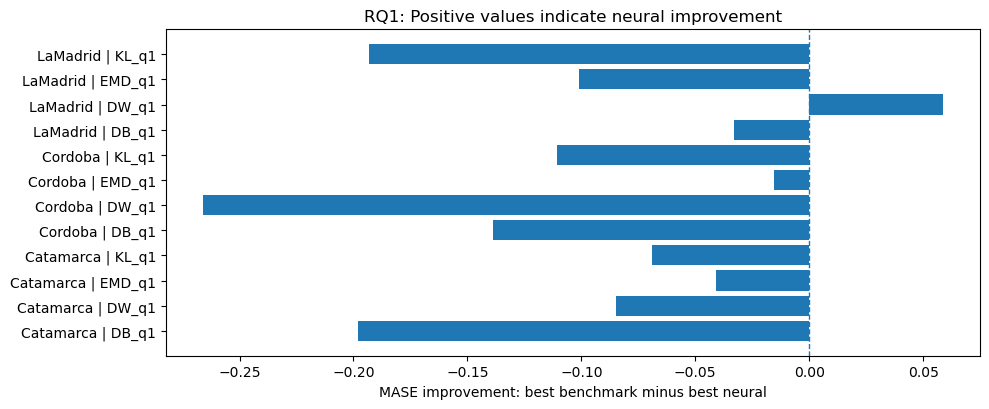

In [17]:
if not rq1_best_comparison.empty:
    plot_df = rq1_best_comparison.copy()
    plot_df["case"] = plot_df["station"] + " | " + plot_df["target"]
    plt.figure(figsize=(10, max(4, 0.35 * len(plot_df))))
    y_pos = np.arange(len(plot_df))
    plt.barh(y_pos, plot_df["MASE_improvement_baseline_minus_neural"])
    plt.axvline(0, linestyle="--", linewidth=1)
    plt.yticks(y_pos, plot_df["case"])
    plt.xlabel("MASE improvement: best benchmark minus best neural")
    plt.title("RQ1: Positive values indicate neural improvement")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "RQ1_MASE_improvement_best_neural_vs_best_benchmark.png", dpi=300)
    plt.show()

## 14. RQ2 reference-window sensitivity analysis

,reference_years,station,target,mean,std,median,max
0,10,Catamarca,KL_q1,0.153987,0.263591,0.071968,1.408380
1,10,Catamarca,DW_q1,285.980017,482.946093,104.503378,2604.365900
2,10,Catamarca,DB_q1,0.030166,0.036502,0.016374,0.164916
3,10,Catamarca,EMD_q1,25.668605,17.072649,22.250000,82.250000
4,10,Cordoba,KL_q1,0.088580,0.091876,0.057646,0.364675
5,10,Cordoba,DW_q1,205.085730,295.863804,81.000980,1299.925097
6,10,Cordoba,DB_q1,0.021967,0.021226,0.012289,0.085882
7,10,Cordoba,EMD_q1,25.011628,16.161937,22.500000,71.500000
8,10,LaMadrid,KL_q1,0.054907,0.067274,0.030920,0.283573
9,10,LaMadrid,DW_q1,206.969840,443.017757,64.017243,2601.744524


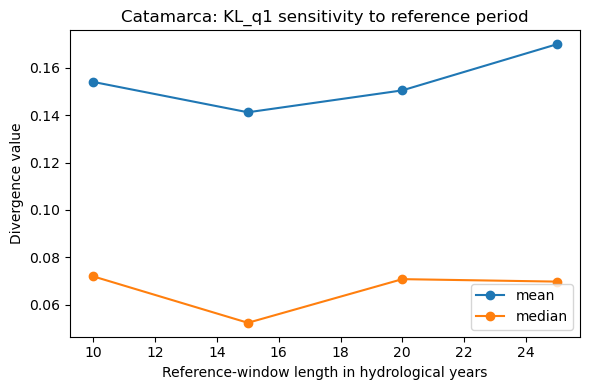

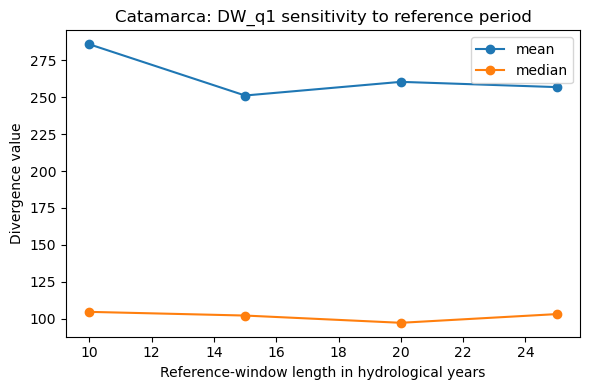

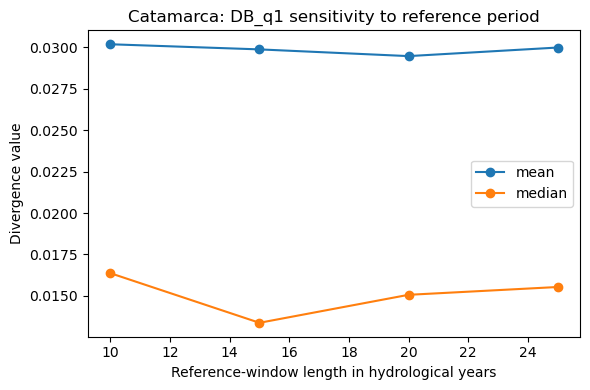

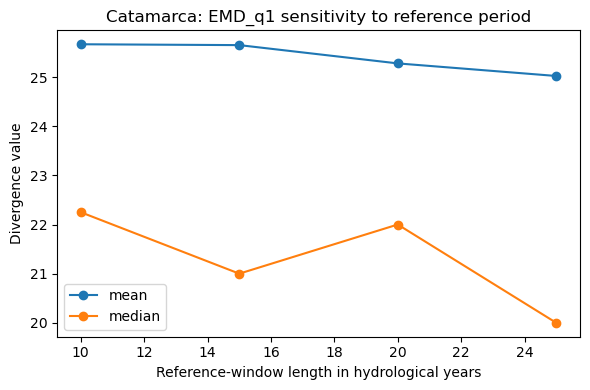

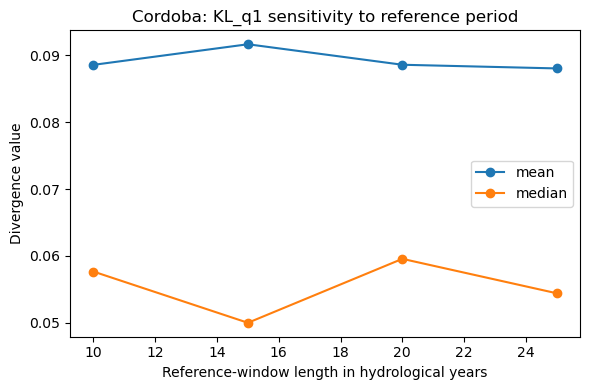

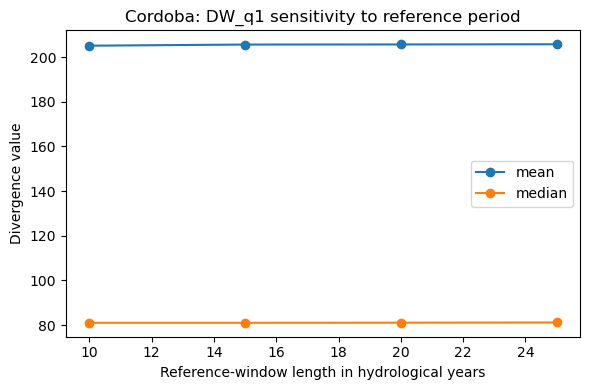

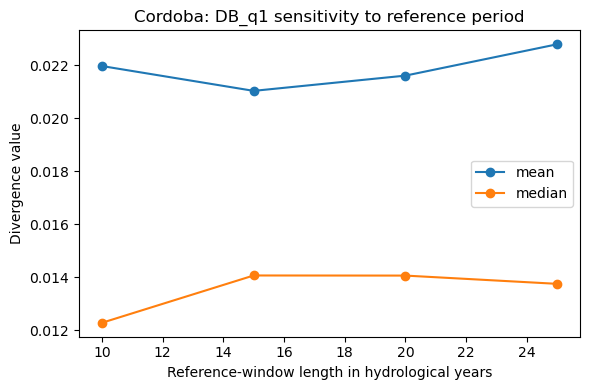

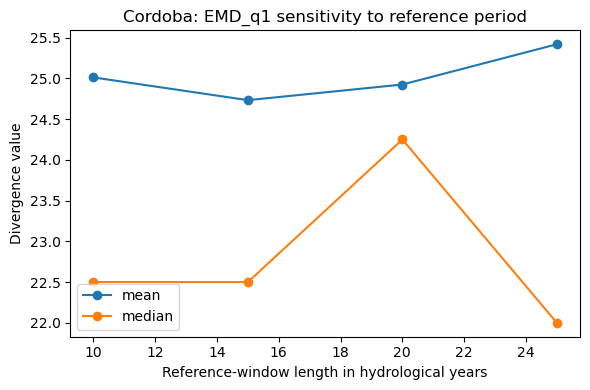

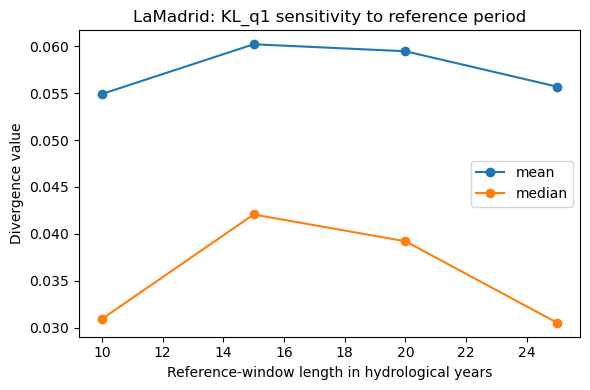

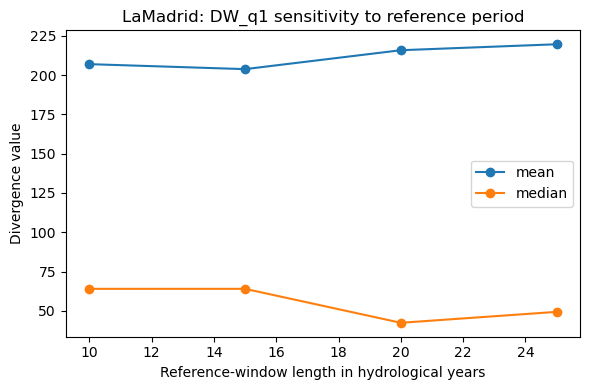

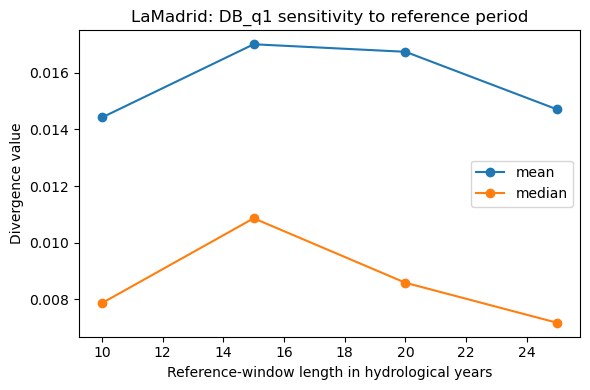

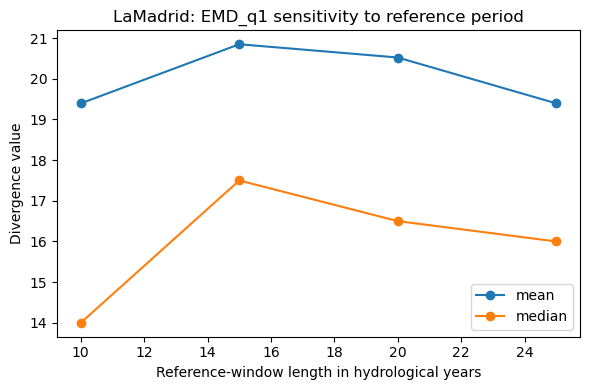

In [18]:
reference_windows = [10, 15, 20, 25]
sensitivity_rows = []

for ref_years in reference_windows:
    temp = add_deterministic_uncertainty_measures(annual, reference_years=ref_years)
    for station, g in temp.groupby("station"):
        for target in TARGETS:
            if target not in g.columns:
                continue
            sensitivity_rows.append({
                "reference_years": ref_years,
                "station": station,
                "target": target,
                "mean": float(g[target].mean()),
                "std": float(g[target].std()),
                "median": float(g[target].median()),
                "max": float(g[target].max())
            })

rq2_reference_sensitivity = pd.DataFrame(sensitivity_rows)
rq2_reference_sensitivity.to_csv(OUTPUT_DIR / "RQ2_reference_window_sensitivity.csv", index=False)
display(rq2_reference_sensitivity.head(20))

for station in rq2_reference_sensitivity["station"].unique():
    for target in TARGETS:
        g = rq2_reference_sensitivity[
            (rq2_reference_sensitivity["station"] == station) &
            (rq2_reference_sensitivity["target"] == target)
        ]
        if g.empty:
            continue
        plt.figure(figsize=(6, 4))
        plt.plot(g["reference_years"], g["mean"], marker="o", label="mean")
        plt.plot(g["reference_years"], g["median"], marker="o", label="median")
        plt.title(f"{station}: {target} sensitivity to reference period")
        plt.xlabel("Reference-window length in hydrological years")
        plt.ylabel("Divergence value")
        plt.legend()
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"RQ2_reference_sensitivity_{station}_{target}.png", dpi=300)
        plt.show()

## 15. Paper-ready result summaries

In [19]:
paper_rq1_table = (
    rq1_metrics
    .sort_values(["station", "target", "MASE"])
    .groupby(["station", "target"])
    .head(5)
    .reset_index(drop=True)
)
paper_rq1_table.to_csv(OUTPUT_DIR / "Paper_Table_RQ1_top5_models_per_station_target.csv", index=False)

paper_rq2_table = rq2_correlations.copy()
paper_rq2_table["abs_spearman_rho"] = paper_rq2_table["spearman_rho"].abs()
paper_rq2_table = (
    paper_rq2_table
    .sort_values(["station", "target", "abs_spearman_rho"], ascending=[True, True, False])
    .groupby(["station", "target"])
    .head(5)
    .reset_index(drop=True)
)
paper_rq2_table.to_csv(OUTPUT_DIR / "Paper_Table_RQ2_top_correlations_with_rainfall_descriptors.csv", index=False)

display(paper_rq1_table.head(30))
display(paper_rq2_table.head(30))

,station,target,model,model_family,n_train,n_val,n_test,MSE,RMSE,MAE,MASE,nRMSE,NMSE
0,Catamarca,DB_q1,XGBoost,benchmark,25,5,7,0.002510,0.050101,0.037821,1.156262,0.433316,0.996345
1,Catamarca,DB_q1,RandomForest,benchmark,25,5,7,0.002997,0.054740,0.044212,1.351639,0.473442,1.189415
2,Catamarca,DB_q1,LSTM,neural,25,5,7,0.002906,0.053909,0.044291,1.354067,0.466251,1.153557
3,Catamarca,DB_q1,TCN,neural,25,5,7,0.003610,0.060081,0.044930,1.373597,0.519635,1.432835
4,Catamarca,DB_q1,Climatology,benchmark,25,5,7,0.003070,0.055406,0.045893,1.403020,0.479201,1.218527
5,Catamarca,DW_q1,MLP_flat,benchmark,25,5,7,765033.642192,874.662016,392.767169,1.529254,0.371691,1.219417
6,Catamarca,DW_q1,XGBoost,benchmark,25,5,7,734309.049647,856.918345,394.421645,1.535696,0.364151,1.170444
7,Catamarca,DW_q1,Climatology,benchmark,25,5,7,669537.945652,818.252984,405.909418,1.580424,0.347720,1.067203
8,Catamarca,DW_q1,TFT_style,neural,25,5,7,664515.313817,815.178087,414.499581,1.613870,0.346413,1.059197
9,Catamarca,DW_q1,BoundedARIMA,benchmark,25,5,7,657504.310741,810.866395,428.594284,1.668749,0.344581,1.048022


,station,target,feature,spearman_rho,p_value,abs_spearman_rho
0,Catamarca,DB_q1,rx7day_mm,0.245394,0.112717,0.245394
1,Catamarca,DB_q1,rx5day_mm,0.239203,0.122380,0.239203
2,Catamarca,DB_q1,rx3day_mm,0.197221,0.204922,0.197221
3,Catamarca,DB_q1,rx1day_mm,0.177974,0.253534,0.177974
4,Catamarca,DB_q1,sigma_left,-0.093903,0.549208,0.093903
5,Catamarca,DW_q1,mu_day,0.309157,0.043669,0.309157
6,Catamarca,DW_q1,rx5day_mm,0.297644,0.052567,0.297644
7,Catamarca,DW_q1,rx7day_mm,0.289037,0.060131,0.289037
8,Catamarca,DW_q1,rx3day_mm,0.245696,0.112261,0.245696
9,Catamarca,DW_q1,rx1day_mm,0.176766,0.256823,0.176766
